## Taller 10 - Redes Neuronales Artificiales

### Integrantes
* Wilmer Santiago
* Bryan Montoya
* Andrea Quintero

## Imports

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

## Desarrollo

El objetivo es clasificar imágenes de dígitos escritos con una red neuronal multicapa (`MLPClassifier`) y comparar cuatro funciones de activación en la capa oculta: `identity`, `logistic`, `tanh` y `relu`. Se comparan la precisión y el tiempo de entrenamiento para decidir cuál conviene usar.

### Pre-entrenamiento y análisis

In [2]:
digits = load_digits()
X = digits.data
y = digits.target

print("Forma de X: ", X.shape)
print("Forma de y: ", y.shape)
print("Clases:", np.unique(y))
print("Rango de valores: ", X.min(), " - ", X.max())
print(f"Exploración de los dígitos \n{pd.Series(y).value_counts().sort_index()}")

Forma de X:  (1797, 64)
Forma de y:  (1797,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Rango de valores:  0.0  -  16.0
Exploración de los dígitos 
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


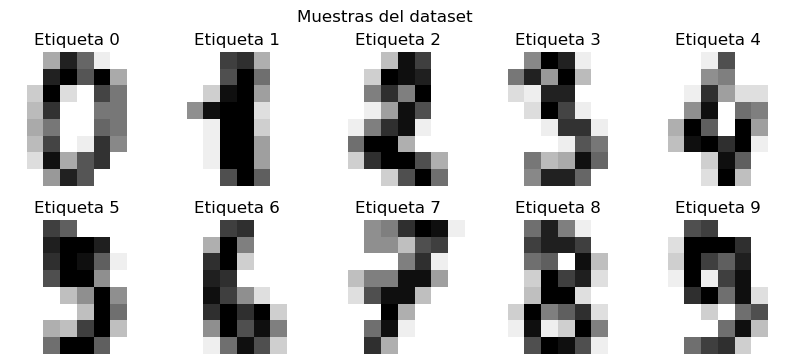

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10,4))
for i, ax in enumerate(axes.flat):
  ax.imshow(digits.images[i], cmap='gray_r')
  ax.set_title(f"Etiqueta {y[i]}")
  ax.axis('off')
plt.suptitle("Muestras del dataset")
plt.show()

**Partición y escalado.** Los datos se dividen en 80 % para entrenamiento (1437 muestras) y 20 % para prueba (360 muestras), con `random_state=42` para que el resultado sea reproducible.

Luego se estandarizan con `StandardScaler` para que cada característica tenga media 0 y desviación 1. Las redes neuronales entrenan mejor con entradas en escalas similares: los gradientes quedan mejor condicionados y las activaciones `logistic`/`tanh` no se saturan desde el inicio. El escalador se ajusta **solo con el conjunto de entrenamiento** y después se aplica al de prueba, para no filtrar información del test.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Entrenamiento: ", X_train.shape)
print("Prueba: ", X_test.shape)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Media y desviación de datos tras escalar los datos: ")
print("Media train: ", X_train.mean().round(3))
print("Desviación train: ", X_train.std().round(3))

Entrenamiento:  (1437, 64)
Prueba:  (360, 64)
Media y desviación de datos tras escalar los datos: 
Media train:  -0.0
Desviación train:  0.976


### Características de las funciones

| Función | Fórmula | Rango | Características |
|---|---|---|---|
| **identity** | f(z) = z | (-∞, ∞) | Lineal: no transforma nada. Toda la red colapsa en un modelo lineal (como una regresión logística), por lo que no puede aprender relaciones no lineales. |
| **logistic** (sigmoide) | f(z) = 1 / (1 + e⁻ᶻ) | (0, 1) | Suave y clásica. Se satura en los extremos: su derivada es máximo 0.25 y tiende a 0, causando el problema del *gradiente que se desvanece*, lo que hace el aprendizaje lento. |
| **tanh** | f(z) = (eᶻ − e⁻ᶻ) / (eᶻ + e⁻ᶻ) | (-1, 1) | Similar a la sigmoide pero centrada en 0 y con derivada máxima de 1, por lo que suele converger más rápido que logistic. También se satura en los extremos. |
| **relu** | f(z) = max(0, z) | [0, ∞) | Muy barata de calcular y no se satura para z > 0 (derivada = 1), por lo que entrena rápido. Es la más usada actualmente. Desventaja: neuronas que siempre reciben z < 0 quedan "muertas" |

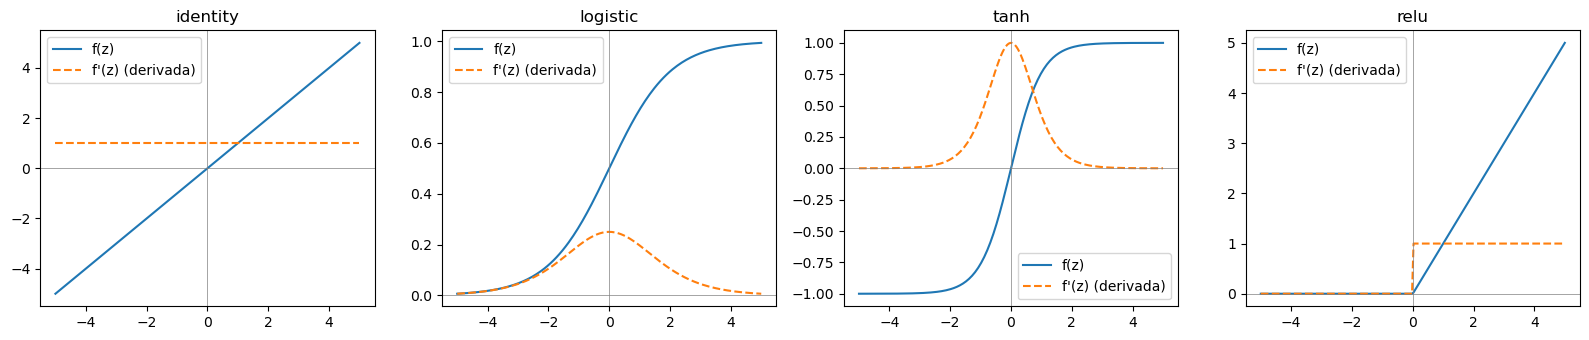

In [5]:
z = np.linspace(-5, 5, 200)

funciones = {
    'identity': (z,                      np.ones_like(z)),
    'logistic': (1 / (1 + np.exp(-z)),   (1 / (1 + np.exp(-z))) * (1 - 1 / (1 + np.exp(-z)))),
    'tanh':     (np.tanh(z),             1 - np.tanh(z)**2),
    'relu':     (np.maximum(0, z),       (z > 0).astype(float)),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (nombre, (f, df)) in zip(axes, funciones.items()):
    ax.plot(z, f, label='f(z)')
    ax.plot(z, df, '--', label="f'(z) (derivada)")
    ax.set_title(nombre)
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

**Observación:** Las derivadas de logistic y tanh se acercan a 0 cuando |z| es grande (saturación), mientras que la de relu se mantiene en 1 para z > 0. Por esto se espera que relu y tanh entrenen más rápido que logistic, y que identity tenga menor capacidad al ser lineal.

### Entrenamiento

**Arquitectura de la red:**
- **Capa de entrada:** 64 neuronas, una por píxel.
- **Capa oculta:** 100 neuronas (`hidden_layer_sizes=(100,)`). Su función de activación es la que se compara.
- **Capa de salida:** 10 neuronas, una por dígito, con *softmax* (sklearn la aplica automáticamente en clasificación multiclase).

Los cuatro modelos usan exactamente la misma configuración y solo cambia la activación, así que las diferencias se deben a ella. El tiempo medido corresponde únicamente a `fit`, es decir, al entrenamiento.

In [6]:
activaciones =  ['identity', 'logistic', 'tanh', 'relu']
resultados = []
modelos = {}

for activacion in activaciones:
    print(f"Entrenando con función de activación {activacion}")
    mlp = MLPClassifier(hidden_layer_sizes=(100,), activation=activacion, max_iter=1000, random_state=42)
    inicio = time.time()
    mlp.fit(X_train, y_train)
    tiempo = time.time() - inicio

    acc_train = accuracy_score(y_train, mlp.predict(X_train))
    acc_test = accuracy_score(y_test, mlp.predict(X_test))
    modelos[activacion] = mlp
    resultados.append({
        'activacion': activacion,
        'time': tiempo,
        'acc_train': acc_train,
        'acc_test': acc_test,
        'iter': mlp.n_iter_
    })
    print(f"accuracy_train: {acc_train:.4f} | accuracy_test: {acc_test:.4f} | time: {tiempo:.3f}s | iter: {mlp.n_iter_}")


Entrenando con función de activación identity
accuracy_train: 1.0000 | accuracy_test: 0.9639 | time: 0.696s | iter: 223
Entrenando con función de activación logistic
accuracy_train: 1.0000 | accuracy_test: 0.9778 | time: 1.204s | iter: 299
Entrenando con función de activación tanh
accuracy_train: 1.0000 | accuracy_test: 0.9750 | time: 0.885s | iter: 178
Entrenando con función de activación relu
accuracy_train: 1.0000 | accuracy_test: 0.9806 | time: 0.574s | iter: 149


In [7]:
df = pd.DataFrame(resultados).set_index('activacion')
df.round(4)

,time,acc_train,acc_test,iter
activacion,,,,
identity,0.6956,1.0,0.9639,223
logistic,1.2036,1.0,0.9778,299
tanh,0.8854,1.0,0.9750,178
relu,0.5743,1.0,0.9806,149


### Evaluación del mejor modelo

Se toma el modelo con mayor *accuracy* en prueba y se analiza su desempeño por clase con la matriz de confusión y el reporte de clasificación.

Mejor activación: relu | accuracy_test: 0.9806

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        33
           1     1.0000    1.0000    1.0000        28
           2     1.0000    1.0000    1.0000        33
           3     0.9706    0.9706    0.9706        34
           4     0.9787    1.0000    0.9892        46
           5     0.9783    0.9574    0.9677        47
           6     0.9714    0.9714    0.9714        35
           7     1.0000    0.9706    0.9851        34
           8     0.9677    1.0000    0.9836        30
           9     0.9500    0.9500    0.9500        40

    accuracy                         0.9806       360
   macro avg     0.9817    0.9820    0.9818       360
weighted avg     0.9806    0.9806    0.9805       360



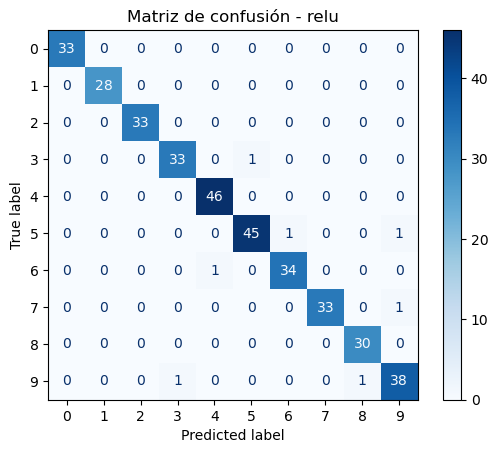

In [8]:
mejor = df['acc_test'].idxmax()
mejor_modelo = modelos[mejor]
y_pred = mejor_modelo.predict(X_test)
print(f"Mejor activación: {mejor} | accuracy_test: {df.loc[mejor, 'acc_test']:.4f}\n")
print(classification_report(y_test, y_pred, digits=4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title(f"Matriz de confusión - {mejor}")
plt.show()

### Análisis de resultados y conclusión

| Activación | Accuracy prueba | Tiempo (s) | Iteraciones |
|---|---|---|---|
| identity | 0.9639 | ~0.78 | 223 |
| logistic | 0.9778 | ~1.46 | 299 |
| tanh | 0.9750 | ~1.00 | 178 |
| relu | **0.9806** | **~0.67** | **149** |

- **identity** obtiene la menor precisión en prueba. Sin una función no lineal, la red equivale a un clasificador lineal (una regresión logística multinomial). Aun así logra ~96 %, porque `digits` es casi linealmente separable en 64 dimensiones.
- **logistic** generaliza bien, pero es la más lenta: necesita más iteraciones y cada una cuesta más. Esto confirma que su derivada es como máximo 0.25 y se satura, lo que hace lento el aprendizaje.
- **tanh** está centrada en 0 y su derivada máxima es 1, por eso converge en menos iteraciones que logistic y tarda aproximadamente un tercio menos con una precisión similar.
- **relu** obtiene la mejor precisión y es, con diferencia, la más rápida. Alrededor de 2 veces más rápida que logistic y 1.5 veces más que tanh. Su cálculo (`max(0, z)`) es trivial y su gradiente no se desvanece para z > 0.

**Sobre la magnitud de las diferencias:** con 360 muestras de prueba, cada acierto equivale a 0.0028 del *accuracy*. Por ende, las diferencias de precisión entre logistic, tanh y relu son de aproximadamente 1 a 2 imágenes, por lo que no solo podemos concluir con el *accuracy*. La diferencia nos la da el tiempo de entrenameinto que sí es consistente: relu tarda menos que todas, y logistic tarda el doble; de ahí concluimos quién es mejor que otra.

**Conclusión:** conviene usar **relu** porque ofrece la mejor precisión con el menor tiempo de entrenamiento y en el menor número de iteraciones. En redes más grandes o con más datos esa ventaja en tiempo se vuelve todavía aún más importante.